# AI for Actuaries : Hackathon 2026

## Week 1: Build your Pricing Approach

**Objective**

Predict the expected ultimate net claim cost (risk premium) for each policy-period in 2025, net of policy excess and recoveries, excluding repudiated claims.

The modelling approach is based on:

$ \text{Expected Claim Cost} = \text{Exposure} \times \text{Frequency} \times \text{Severity} $



In [1]:
# Install packages
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

# EDA
from data_profiling import ProfileReport

# Models

#warnings.filterwarnings('ignore')

/Users/sarahguilliams/anaconda3/envs/hackathon/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step-by-Step Analysis

### 1. Data Understanding
Load dataset

Show first few rows

Key observations

In [2]:
#Read the datasets
from pathlib import Path

data_dir = Path("data")
if not data_dir.is_dir():
    raise FileNotFoundError(f"Data directory not found: {data_dir.resolve()}")

parquet_files = sorted(data_dir.glob("*.parquet"))
if not parquet_files:
    raise FileNotFoundError(f"No Parquet datasets found in {data_dir.resolve()}")

datasets = {path.stem: pd.read_parquet(path) for path in parquet_files}

display(pd.DataFrame(
    [
        {"dataset": name, "rows": len(df), "columns": len(df.columns), "duplicate rows": df.duplicated().sum()}
        for name, df in datasets.items()
    ]
))

for name, df in datasets.items():
    print(f"\nFirst 10 rows of {name}:")
    print(df.head(10).to_string(index=False))

,dataset,rows,columns,duplicate rows
0,addresses,575983,16,0
1,claims,163150,12,0
2,customers,545240,18,0
3,policies_buildings,707726,27,0
4,policies_contents,721617,28,0
5,policies_motor,979968,39,0
6,sample_submission,626639,2,0
7,test_buildings,184155,26,0
8,test_contents,187498,27,0
9,test_motor,254986,38,0



First 10 rows of addresses:
address_id region urban_density  flood_zone  distance_to_river_km  elevation_m soil_type  year_built property_type roof_type  basement  trees_within_5m  listed_building  bedrooms energy_rating  solar_panels
  A1980663    R05      suburban         1.0                  4.10          9.2      clay        2014      terraced   pitched     False            False            False         3             A         False
  A7251041    R12         urban         1.0                  0.39          4.0     chalk        1969      terraced   pitched     False            False            False         4             C         False
  A4921189    R11         rural         2.0                  0.41         60.0      clay        1952      terraced   pitched     False            False            False         3             C         False
  A9620763    R04         urban         1.0                  6.89          4.7      clay        1881          flat   pitched     False         

### 2. Data Preparation

Objective: Ensure that each row represents a valid policy-period and that reference tables have unique keys. \
Below the table we can see that the average exposure in the policies is more than 1 year.

In [3]:
customers = datasets["customers"].copy()
addresses = datasets["addresses"].copy()
weather = datasets["weather"].copy()
claims = datasets["claims"].copy()

train = {
    line: datasets[f"policies_{line}"].copy()
    for line in ["motor", "buildings", "contents"]
}

test = {
    line: datasets[f"test_{line}"].copy()
    for line in ["motor", "buildings", "contents"]
}

# 1. Check unique keys
print("=== REFERENCE TABLE CHECKS ===")

for name, df, keys in [
    ("customers", customers, ["customer_id"]),
    ("addresses", addresses, ["address_id"]),
    ("weather", weather, ["address_id", "year"]),
    ("claims", claims, ["claim_id"])
]:
    duplicates = df.duplicated(subset=keys).sum()
    status = "PASS" if duplicates == 0 else "FAIL"
    print(f"{name:20} | {status} | Duplicate keys: {duplicates}")

# 2. Check policy-period structure
print("\n=== POLICY-PERIOD CHECKS ===")

results = []

for line in ["motor", "buildings", "contents"]:
    for dataset_type, df in [
        ("train", train[line]),
        ("test", test[line])
    ]:
        df["period_start"] = pd.to_datetime(df["period_start"])
        df["period_end"] = pd.to_datetime(df["period_end"])

        results.append({
            "dataset": f"{dataset_type}_{line}",
            "rows": len(df),
            "duplicate_row_ids": df["row_id"].duplicated().sum(),
            "invalid_dates": (
                df["period_start"] > df["period_end"]
            ).sum(),
            "missing_exposure": df["exposure"].isna().sum(),
            "nonpositive_exposure": (df["exposure"] <= 0).sum(),
            "total_exposure": df["exposure"].sum(),
            "average_exposure": df["exposure"].mean()
        })

quality_report = pd.DataFrame(results)

display(quality_report)

=== REFERENCE TABLE CHECKS ===
customers            | PASS | Duplicate keys: 0
addresses            | PASS | Duplicate keys: 0
weather              | PASS | Duplicate keys: 0
claims               | PASS | Duplicate keys: 0

=== POLICY-PERIOD CHECKS ===


,dataset,rows,duplicate_row_ids,invalid_dates,missing_exposure,nonpositive_exposure,total_exposure,average_exposure
0,train_motor,979968,0,0,0,0,1.058510e+06,1.080147
1,test_motor,254986,0,0,0,0,1.999836e+05,0.784292
2,train_buildings,707726,0,0,0,0,7.894039e+05,1.115409
3,test_buildings,184155,0,0,0,0,1.502439e+05,0.815856
4,train_contents,721617,0,0,0,0,8.107226e+05,1.123480
5,test_contents,187498,0,0,0,0,1.501238e+05,0.800669


From performing these checks we notice that the exposure has a value that is larger than 1. This is not possible as the description of the dataset indicated that each line in the policy datasets in one calender year for each policy.
Checking the exposures indicates that there are some inconsistencies in the data. 

In [4]:
# Check the exposures:
for line in ["motor", "buildings", "contents"]:

    df = datasets[f"policies_{line}"]

    print(f"\n=== {line.upper()} ===")

    print(df["exposure"].describe(
        percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
    ))

    print("Rows with exposure > 1:",
          (df["exposure"] > 1).sum())

    print("Maximum exposure:", df["exposure"].max())

for line in ["motor", "buildings", "contents"]:

    df = datasets[f"policies_{line}"]

    exposure_above_1 = df[df["exposure"] > 1]

    print(f"\n=== {line.upper()} ===")
    print(f"Number of rows with exposure > 1: {len(exposure_above_1)}")

    #display(exposure_above_1)


=== MOTOR ===
count    979968.000000
mean          1.080147
std           9.635858
min           0.002700
1%            0.021900
25%           0.638400
50%           1.000000
75%           1.000000
95%           1.000000
99%           1.000000
max         365.000000
Name: exposure, dtype: float64
Rows with exposure > 1: 3991
Maximum exposure: 365.0

=== BUILDINGS ===
count    707726.000000
mean          1.115409
std           9.779618
min           0.002700
1%            0.027400
25%           0.764400
50%           1.000000
75%           1.000000
95%           1.000000
99%           1.000000
max         365.000000
Name: exposure, dtype: float64
Rows with exposure > 1: 3044
Maximum exposure: 365.0

=== CONTENTS ===
count    721617.00000
mean          1.12348
std          10.16077
min           0.00270
1%            0.02470
25%           0.69860
50%           1.00000
75%           1.00000
95%           1.00000
99%           1.00000
max         365.00000
Name: exposure, dtype: float64
R

In [5]:
# Recalculate exposure quality report

results = []

for line in ["motor", "buildings", "contents"]:
    for dataset_type, df in [
        ("train", train[line]),
        ("test", test[line])
    ]:

        df["period_start"] = pd.to_datetime(df["period_start"])
        df["period_end"] = pd.to_datetime(df["period_end"])

        # Recalculate exposure based on actual days covered
        days_covered = (
            df["period_end"] - df["period_start"]
        ).dt.days + 1

        # Account for leap years
        days_in_year = np.where(
            df["period_start"].dt.is_leap_year,
            366,
            365
        )

        df["exposure_corrected"] = days_covered / days_in_year

        # Build quality report using corrected exposure
        results.append({
            "dataset": f"{dataset_type}_{line}",
            "rows": len(df),
            "duplicate_row_ids": df["row_id"].duplicated().sum(),
            "invalid_dates": (
                df["period_start"] > df["period_end"]
            ).sum(),
            "missing_exposure": df["exposure_corrected"].isna().sum(),
            "nonpositive_exposure": (
                df["exposure_corrected"] <= 0
            ).sum(),
            "total_exposure": df["exposure_corrected"].sum(),
            "average_exposure": df["exposure_corrected"].mean(),
            "max_exposure": df["exposure_corrected"].max(),
            "original_average_exposure": df["exposure"].mean()
        })

quality_report = pd.DataFrame(results)

display(quality_report.round(4))

,dataset,rows,duplicate_row_ids,invalid_dates,missing_exposure,nonpositive_exposure,total_exposure,average_exposure,max_exposure,original_average_exposure
0,train_motor,979968,0,0,0,0,786611.6609,0.8027,1.0,1.0801
1,test_motor,254986,0,0,0,0,199983.5808,0.7843,1.0,0.7843
2,train_buildings,707726,0,0,0,0,590150.5701,0.8339,1.0,1.1154
3,test_buildings,184155,0,0,0,0,150243.9041,0.8159,1.0,0.8159
4,train_contents,721617,0,0,0,0,590449.5397,0.8182,1.0,1.1235
5,test_contents,187498,0,0,0,0,150123.7699,0.8007,1.0,0.8007


In [6]:
# After performing the exposure correction, we will update the original exposure column with the corrected values in both train and test datasets.
for line in train:
    train[line]["exposure"] = train[line]["exposure_corrected"]

for line in test:
    test[line]["exposure"] = test[line]["exposure_corrected"]


Merge customer and adress info.
Objective: Enrich policy-level features before building the target.
These are many-to-one joins: each policy-period belongs to one customer and references one insured address.

In [7]:
def enrich_static_features(df, line, dataset_name):
    initial_rows = len(df)

    enriched = df.merge(
        customers,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )

    enriched = enriched.merge(
        addresses,
        on="address_id",
        how="left",
        validate="many_to_one"
    )

    enriched_rows = len(enriched)
    if enriched_rows != initial_rows:
        print(
            f"{dataset_name} {line}: FAIL — row count changed from "
            f"{initial_rows} to {enriched_rows}"
        )
        raise ValueError(
            f"Row count changed during customer/address enrichment "
            f"for {dataset_name} {line}"
        )

    print(f"{dataset_name} {line}: PASS — row count unchanged ({initial_rows})")

    return enriched


print("Check AI code:")

train = {
    line: enrich_static_features(df, line, "Train")
    for line, df in train.items()
}

test = {
    line: enrich_static_features(df, line, "Test")
    for line, df in test.items()
}

Check AI code:
Train motor: PASS — row count unchanged (979968)
Train buildings: PASS — row count unchanged (707726)
Train contents: PASS — row count unchanged (721617)
Test motor: PASS — row count unchanged (254986)
Test buildings: PASS — row count unchanged (184155)
Test contents: PASS — row count unchanged (187498)


#### Step 4 — Engineer historical weather features
Objective: Add weather risk information without using future observations.
We should not use actual weather from 2025 to predict 2025 risk premium. Equally, for a 2023 policy we should not use actual weather outcomes from 2023 when simulating a prediction made at inception.
A starting approach is to use previous-year weather.

In [8]:
# Identify weather variables
weather_columns = [
    col for col in weather.columns
    if col not in ["address_id", "year"]
]

# Rename weather columns to indicate lagged features
weather_lagged = weather.rename(
    columns={
        "year": "previous_year",
        **{
            col: f"lag1_{col}"
            for col in weather_columns
        }
    }
)

# Check uniqueness of weather records
assert not weather_lagged.duplicated(
    subset=["address_id", "previous_year"]
).any(), "Duplicate address-year combinations in weather data"


# Function to merge historical weather
def merge_weather(df, line, dataset_name):

    result = df.copy()

    # Derive year from the policy-period start date
    result["period_start"] = pd.to_datetime(
        result["period_start"]
    )

    result["year"] = result["period_start"].dt.year

    # Use 2021 weather for 2021 policies,
    # previous-year weather for all subsequent years
    result["previous_year"] = np.where(
        result["year"] == 2021,
        2021,
        result["year"] - 1
    )

    original_rows = len(result)

    # Merge weather
    result = result.merge(
        weather_lagged,
        on=["address_id", "previous_year"],
        how="left",
        validate="many_to_one"
    )

    # Check row count
    merged_rows = len(result)

    if merged_rows != original_rows:
        print(
            f"{dataset_name} {line}: FAIL — row count changed from "
            f"{original_rows} to {merged_rows}"
        )
        raise ValueError(
            f"Row count changed during weather enrichment "
            f"for {dataset_name} {line}"
        )

    print(
        f"{dataset_name} {line}: PASS — "
        f"row count unchanged ({original_rows:,})"
    )

    return result.drop(columns="previous_year")


# For now also add weather data to motor
print("Check weather enrichment:")

# Apply to training datasets
train = {
    line: merge_weather(df, line, "Train")
    for line, df in train.items()
}

# Apply to test datasets
test = {
    line: merge_weather(df, line, "Test")
    for line, df in test.items()
}

Check weather enrichment:
Train motor: PASS — row count unchanged (979,968)
Train buildings: PASS — row count unchanged (707,726)
Train contents: PASS — row count unchanged (721,617)
Test motor: PASS — row count unchanged (254,986)
Test buildings: PASS — row count unchanged (184,155)
Test contents: PASS — row count unchanged (187,498)


#### Step 5 — Match claims to the correct policy-period
Objective: Assign every historical claim to the exact row covering its loss date.
This is the most important merge in the workflow.
We cannot join claims only on policy_id, because a policy may have multiple rows across different years or mid-term changes. So we do not first perform aggregation on the claims table with policy_id and loss year because there might be multiple policy versions within a year.


First, combine the policy-period identifiers into a temporary lookup table. This includes the policy_id and the start and end date of that version of the policy.

At the end there are some claims that are unmatched. As an actuary, it is necesarry to perform a check on the data to understand why this occurs. A diagnostic indicates that the loss date occured before the start date of the policy. In the majority of the cases, the reporting date did occur when a policy was risk-bearing. Therefore, the decision is made to link the "unmatched" cases to the policy such that loss date is nearest to the policy instance.

In [9]:
policy_windows = pd.concat(
    [
        datasets[f"policies_{line}"][
            ["row_id", "policy_id", "period_start", "period_end"]
        ].assign(line=line)
        for line in ["motor", "buildings", "contents"]
    ],
    ignore_index=True
)

policy_windows["period_start"] = pd.to_datetime(
    policy_windows["period_start"]
)
policy_windows["period_end"] = pd.to_datetime(
    policy_windows["period_end"]
)


## Exclude repudiated claims, then match the remaining claims to policy periods.
claims_for_matching = claims.loc[
    claims["status"] != "repudiated"
].copy()
claims_for_matching["loss_date"] = pd.to_datetime(
    claims_for_matching["loss_date"]
)

claims_with_policy_windows = claims_for_matching.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="left"
)

claims_matched = claims_with_policy_windows.loc[
    (claims_with_policy_windows["loss_date"] >= claims_with_policy_windows["period_start"])
    &
    (claims_with_policy_windows["loss_date"] <= claims_with_policy_windows["period_end"])
].copy()

print("Claims excluded (repudiated):", len(claims) - len(claims_for_matching))
print("Claims included in matching:", len(claims_for_matching))
print("Matched claims:", len(claims_matched))

print(
    "Claims with multiple matches:",
    claims_matched["claim_id"].duplicated().sum()
)

assert claims_matched["claim_id"].is_unique

unmatched_claims = claims_for_matching.loc[
    ~claims_for_matching["claim_id"].isin(claims_matched["claim_id"])
].copy()

unmatched_policy_windows = unmatched_claims.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="left",
    indicator=True
)

policy_window_summary = (
    unmatched_policy_windows.groupby("claim_id")
    .agg(
        policy_found=("_merge", lambda matches: matches.eq("both").any()),
        first_period_start=("period_start", "min"),
        last_period_end=("period_end", "max")
    )
    .reset_index()
)

unmatched_claim_diagnostics = unmatched_claims[
    ["claim_id", "policy_id", "line", "loss_date",  "report_date"]
].merge(policy_window_summary, on="claim_id", how="left")

reasons = [
    unmatched_claim_diagnostics["loss_date"].isna(),
    ~unmatched_claim_diagnostics["policy_found"],
    unmatched_claim_diagnostics["first_period_start"].isna()
    | unmatched_claim_diagnostics["last_period_end"].isna(),
    unmatched_claim_diagnostics["loss_date"]
    < unmatched_claim_diagnostics["first_period_start"],
    unmatched_claim_diagnostics["loss_date"]
    > unmatched_claim_diagnostics["last_period_end"]
]
reason_labels = [
    "Missing loss date",
    "No matching policy_id and line",
    "Missing policy period dates",
    "Loss before first policy period",
    "Loss after last policy period"
]
unmatched_claim_diagnostics["reason"] = np.select(
    reasons,
    reason_labels,
    default="Gap between policy periods"
)

print("Check AI code:")
print("Unmatched claims:", len(unmatched_claim_diagnostics))
print("Unmatched claim reasons:")
print(unmatched_claim_diagnostics["reason"].value_counts().to_string())



# Find candidate periods for claims that did not match by loss date
nearest_candidates = unmatched_claims.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="inner",
    validate="many_to_many"
)

# Distance is zero if the date is inside the interval; otherwise, use
# the number of days to the nearest period boundary.
nearest_candidates["distance_days"] = np.select(
    [
        nearest_candidates["loss_date"] < nearest_candidates["period_start"],
        nearest_candidates["loss_date"] > nearest_candidates["period_end"],
    ],
    [
        (nearest_candidates["period_start"] - nearest_candidates["loss_date"]).dt.days,
        (nearest_candidates["loss_date"] - nearest_candidates["period_end"]).dt.days,
    ],
    default=0
)

# Select one nearest policy-period for each claim.
nearest_matches = (
    nearest_candidates
    .dropna(subset=["loss_date", "period_start", "period_end"])
    .sort_values(["claim_id", "distance_days", "period_start", "row_id"])
    .drop_duplicates("claim_id", keep="first")
    .copy()
)

nearest_matches["match_method"] = "nearest_period"
claims_matched["match_method"] = "loss_date_within_period"

# Add nearest-period assignments to the existing exact matches.
claims_matched = pd.concat(
    [claims_matched, nearest_matches],
    ignore_index=True
)

assert claims_matched["claim_id"].is_unique

print("Claims assigned to nearest period:", len(nearest_matches))
print("Claims still without a policy period:",
      len(unmatched_claims) - len(nearest_matches))

Claims excluded (repudiated): 1711
Claims included in matching: 161439
Matched claims: 161029
Claims with multiple matches: 0
Check AI code:
Unmatched claims: 410
Unmatched claim reasons:
reason
Loss before first policy period    410
Claims assigned to nearest period: 410
Claims still without a policy period: 0


#### Step 6 — Calculate the observed net incurred claim cost
Objective: Construct a historical cost measure consistent with the target.
According to the data dictionary:
- paid_to_date is already net of excess.
- incurred_to_date consists of paid amounts and the open-claim case estimate.
- recoveries is a separate amount, but it is not confirmed whether incurred already reflects it.
- Repudiated claims must be excluded.

Our provisional assumption is:
$ \text{Observed Net Incurred} = \text{Incurred to Date} - \text{Recoveries} $

We must not deduct the policy excess again.

In [10]:
claims_matched["recoveries"] = (
    claims_matched["recoveries"].fillna(0)
)

# Working assumption: recoveries are NOT yet deducted from incurred_to_date.
RECOVERIES_ALREADY_NETTED = False

if RECOVERIES_ALREADY_NETTED:
    claims_matched["net_cost_before_status"] = (
        claims_matched["incurred_to_date"]
    )
else:
    claims_matched["net_cost_before_status"] = (
        claims_matched["incurred_to_date"]
        - claims_matched["recoveries"]
    )

claims_matched["net_incurred"] = np.where(
    claims_matched["net_cost_before_status"] > 0,
    claims_matched["net_cost_before_status"],
    0
)

# Final reconciliation:
display(
    claims_matched.groupby(["line", "status"]).agg(
        claims=("claim_id", "count"),
        incurred=("incurred_to_date", "sum"),
        recoveries=("recoveries", "sum"),
        net_incurred=("net_incurred", "sum")
    )
)

negative_claims = claims_matched[
    claims_matched["net_incurred"] < 0
]

print("Negative net incurred claims:", len(negative_claims))

claims      incurred   recoveries  net_incurred
line      status                                                 
buildings closed   24549  2.169569e+08         0.00  2.169569e+08
          open      1893  3.124254e+07         0.00  3.124254e+07
contents  closed   22992  6.265879e+07         0.00  6.265879e+07
          open       810  3.470007e+06         0.00  3.470007e+06
motor     closed  103751  3.773012e+08  27678633.34  3.496226e+08
          open      7444  8.210164e+07         0.00  8.210164e+07

Negative net incurred claims: 0


#### Step 7 — Aggregate claims at policy-period level, and per policy level generate the target values:
- $N_{i}$ : number of claims per policy, given that exposure =1.
- the average claims cost, given that N > 0.

Objective: Construct the two historical responses: N and total observed claim cost.


In [11]:
# 1. Define targets
targets = (
    claims_matched
    .groupby("row_id", as_index=False)
    .agg(
        nclaims=("claim_id", "nunique"),
        net_incurred=("net_incurred", "sum")
    )
)

targets["nclaims"] = targets["nclaims"].astype(int)


# 2. Merge targets into each line of business
for line, df in train.items():

    initial_rows = len(df)

    # Remove target columns if cell is rerun
    df = df.drop(
        columns=["nclaims", "net_incurred", "avg_sev"],
        errors="ignore"
    )

    # Merge targets
    df = df.merge(
        targets,
        on="row_id",
        how="left",
        validate="one_to_one"
    )

    # Fill missing values
    df["nclaims"] = df["nclaims"].fillna(0).astype(int)
    df["net_incurred"] = df["net_incurred"].fillna(0)

    # Average severity: 0 when nclaims = 0
    df["avg_sev"] = (
        df["net_incurred"]
        / df["nclaims"].replace(0, np.nan)
    ).fillna(0)


    # Validate
    assert len(df) == initial_rows, (
        f"{line}: Row count changed from "
        f"{initial_rows} to {len(df)}"
    )

    train[line] = df

    print(
        f"{line}: {len(df):,} rows preserved | "
        f"{df['nclaims'].sum():,} claims | "
        f"{df['net_incurred'].sum():,.2f} net incurred"
    )

motor: 979,968 rows preserved | 111,195 claims | 431,724,224.25 net incurred
buildings: 707,726 rows preserved | 26,442 claims | 248,199,474.78 net incurred
contents: 721,617 rows preserved | 23,802 claims | 66,128,796.73 net incurred


#### Step 8 — Assess claim development to ultimate
Objective: Correct the mismatch between observed incurred and ultimate costs.
At 31 December 2024:
- Some 2024 losses are not yet reported (IBNR).
- Some reported claims remain open and may develop.
- Future recoveries may not yet be reflected.
Therefore, modelling observed_net_incurred directly will generally underestimate ultimate loss costs if those effects are material.
Ideally, use historical valuation snapshots to build paid/incurred development triangles. However, the supplied claims table has only one snapshot, so reliable chain-ladder development factors cannot be estimated from this table alone.
If validated development-to-ultimate factors become available, you can apply them at a suitable line/peril/accident-year level.

In [12]:
# No estimated development factors are supplied yet.
# These should NOT be treated as genuine ultimate estimates.

for line in train:
    train[line]["development_factor"] = 1.0

    train[line]["avg_sev"] = (
        train[line]["avg_sev"]
        * train[line]["development_factor"]
    )

Here I want a visualization of how the datasets are cleaned from before , to after and the variables that were added

In [13]:
lines_for_comparison = {
    "Motor": "motor",
    "Buildings": "buildings",
    "Contents": "contents",
}

target_columns = ["nclaims", "avg_sev"]

# Summarize rows, exposure, target availability, and dtype counts.
comparison_rows = []
schema_rows = []

for label, line in lines_for_comparison.items():
    before = datasets[f"policies_{line}"]
    after = train[line]

    comparison_rows.extend([
        {
            "line": label,
            "stage": "Before",
            "rows": len(before),
            "columns": len(before.columns),
            "mean exposure": before["exposure"].mean(),
            "total exposure": before["exposure"].sum(),
            "targets present": "None",
        },
        {
            "line": label,
            "stage": "After",
            "rows": len(after),
            "columns": len(after.columns),
            "mean exposure": after["exposure"].mean(),
            "total exposure": after["exposure"].sum(),
            "targets present": ", ".join(
                col for col in target_columns if col in after.columns
            ),
        },
    ])

    before_cols = set(before.columns)
    after_cols = set(after.columns)

    for col in sorted(before_cols | after_cols):
        schema_rows.append({
            "line": label,
            "column": col,
            "before dtype": str(before[col].dtype) if col in before_cols else "—",
            "after dtype": str(after[col].dtype) if col in after_cols else "—",
            "change": (
                "Added" if col not in before_cols else
                "Removed" if col not in after_cols else
                "Retained"
            ),
        })

comparison_summary = pd.DataFrame(comparison_rows)
schema_comparison = pd.DataFrame(schema_rows)

display(comparison_summary.round(3))
#display(schema_comparison)


,line,stage,rows,columns,mean exposure,total exposure,targets present
0,Motor,Before,979968,39,1.080,1058509.681,None
1,Motor,After,979968,84,0.803,786611.661,"nclaims, avg_sev"
2,Buildings,Before,707726,27,1.115,789403.927,None
3,Buildings,After,707726,72,0.834,590150.570,"nclaims, avg_sev"
4,Contents,Before,721617,28,1.123,810722.569,None
5,Contents,After,721617,73,0.818,590449.540,"nclaims, avg_sev"


In [14]:
print(train["motor"].head(10).to_string())

      row_id  policy_id customer_id address_id period_start period_end  exposure  driver_age  years_licensed  ncb_years  vehicle_value_group  vehicle_age make_model  engine_size_cc  body_type transmission  seats vehicle_colour fuel_type  driver_assist     cover_type  annual_mileage overnight_parking vehicle_use  named_young_driver  telematics_opt_in  telematics_score  voluntary_excess  compulsory_excess          channel payment_method  missed_payments_12m  new_business  renewal_count  days_quote_to_inception  discount_applied  written_premium  customer_service_contacts renewal_decision  exposure_corrected     surname date_of_birth   occupation marital_status  household_size credit_band  prior_claims_5y  licence_points  years_at_address  customer_since_year email_domain marketing_consent document_preference previous_insurer campaign_code  branch_id  marketing_segment region urban_density  flood_zone  distance_to_river_km  elevation_m soil_type  year_built property_type roof_type  baseme

### 3. EDA

In [ ]:
#profile = ProfileReport(datasets["policies_motor"], title="Profiling Report")
#profile.to_widgets()

In [ ]:
claims_plot = datasets["claims"].copy()

# Extract accident year from loss date
claims_plot["loss_date"] = pd.to_datetime(claims_plot["loss_date"])
claims_plot["year"] = claims_plot["loss_date"].dt.year

# Exclude repudiated claims
claims_plot = claims_plot[
    claims_plot["status"] != "repudiated"
].copy()

# Provisional assumption: incurred excludes recoveries
claims_plot["net_claim_cost"] = (
    claims_plot["incurred_to_date"]
    - claims_plot["recoveries"].fillna(0)
)

# Retain positive claim costs for log-scaled distribution plots
claims_plot = claims_plot[
    claims_plot["net_claim_cost"] > 0
].copy()

# Define the colors for each accident year
year_colors = {
    2020: "purple",
    2021: "blue",
    2022: "green",
    2023: "orange",
    2024: "red"
}

sns.set_theme(style="whitegrid")

for line in ["motor", "buildings", "contents"]:

    df_line = claims_plot[
        claims_plot["line"] == line
    ].copy()

    plt.figure(figsize=(12, 6))

    sns.histplot(
        data=df_line,
        x="net_claim_cost",
        hue="year",
        palette=year_colors,
        bins=50,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        log_scale=True
    )

    plt.title(
        f"Distribution of Net Claim Costs — {line.capitalize()}",
        fontsize=14
    )

    plt.xlabel("Net Claim Cost (CU, log scale)")
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

In [ ]:

# Limit analysis to training accident years
plot_data = claims_plot[
    claims_plot["year"].between(2020, 2024)
    & (claims_plot["net_claim_cost"] > 0)
].copy()

year_colors = {
    2020: "purple",
    2021: "blue",
    2022: "green",
    2023: "orange",
    2024: "red"
}

for line in ["motor", "buildings", "contents"]:

    df_line = plot_data[plot_data["line"] == line]

    plt.figure(figsize=(10, 6))

    sns.ecdfplot(
        data=df_line,
        x="net_claim_cost",
        hue="year",
        palette=year_colors
    )

    plt.xscale("log")
    plt.title(f"Net Claim Cost Distribution — {line.capitalize()}")
    plt.xlabel("Net Claim Cost (CU, log scale)")
    plt.ylabel("Cumulative proportion of claims")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

This is particularly useful for identifying whether the differences are in attritional claims or large losses.

In [ ]:
severity_comparison = (
    plot_data.groupby(["line", "year"])["net_claim_cost"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99)
    )
    .round(2)
)

display(severity_comparison)

### 4. Train test split.

In [ ]:

lines = ["motor", "buildings", "contents"]

TARGET = "observed_net_incurred"
EXPOSURE = "exposure"

for line in lines:
    for df in [train[line], test[line]]:
        df["period_start"] = pd.to_datetime(df["period_start"])
        df["year"] = df["period_start"].dt.year

        assert EXPOSURE in df.columns
        assert (df[EXPOSURE] > 0).all()

    assert TARGET in train[line].columns, (
        f"Missing {TARGET} for {line}. "
        "First merge the aggregated claims targets."
    )

    assert train[line][TARGET].notna().all()

    print(
        f"{line}: "
        f"{len(train[line]):,} training rows, "
        f"{len(test[line]):,} test rows"
    )

motor: 979,968 training rows, 254,986 test rows
buildings: 707,726 training rows, 184,155 test rows
contents: 721,617 training rows, 187,498 test rows


In [ ]:
for line in lines:
    df = train[line]

    problematic = df[
        (df["N"] > 0) &
        (df["avg_claim"] <= 0)
    ]

    print(
        line,
        "Claimed periods with non-positive average severity:",
        len(problematic)
    )

motor Claimed periods with non-positive average severity: 1
buildings Claimed periods with non-positive average severity: 0
contents Claimed periods with non-positive average severity: 0


In [ ]:
LINES = ["motor", "buildings", "contents"]

EXPOSURE = "exposure"
FREQUENCY_TARGET = "N"
SEVERITY_TARGET = "avg_claim"

folds = [
    ([2021], 2022),
    ([2021, 2022], 2023),
    ([2021, 2022, 2023], 2024),
]

for line in LINES:
    for df in (train[line], test[line]):
        df["period_start"] = pd.to_datetime(df["period_start"])
        df["year"] = df["period_start"].dt.year

        assert df[EXPOSURE].notna().all()
        assert (df[EXPOSURE] > 0).all()

    df = train[line]

    assert df["row_id"].is_unique
    assert df["N"].notna().all()
    assert (df["N"] >= 0).all()
    #assert df[SEVERITY_TARGET].notna().all()

    # Average cost per claim, only defined for N > 0
    df["avg_claim"] = np.where(
        df["N"] > 0,
        df[SEVERITY_TARGET] / df["N"].replace(0, np.nan),
        np.nan
    )

    print(f"\n{line.upper()}")
    print("Policy periods:", len(df))
    print("Rows with claims:", (df["N"] > 0).sum())
    print("Total claims:", df["N"].sum())
 


MOTOR
Policy periods: 979968
Rows with claims: 98090
Total claims: 110901
Mean severity: 3252.9872688396376

BUILDINGS
Policy periods: 707726
Rows with claims: 25361
Total claims: 26375
Mean severity: 8819.348815389678

CONTENTS
Policy periods: 721617
Rows with claims: 22918
Total claims: 23753
Mean severity: 2626.075344275226


create chronological train/test split

In [23]:
train_split = {}
valid_split = {}

for line in LINES:

    df = train[line]

    train_split[line] = df[
        df["year"].between(2021, 2023)
    ].copy()

    valid_split[line] = df[
        df["year"] == 2024
    ].copy()

    assert len(train_split[line]) > 0
    assert len(valid_split[line]) > 0

    print(f"\n{line.upper()}")
    print("Training years:", sorted(train_split[line]["year"].unique()))
    print("Validation years:", sorted(valid_split[line]["year"].unique()))
    print("Training rows:", len(train_split[line]))
    print("Validation rows:", len(valid_split[line]))


MOTOR
Training years: [np.int32(2021), np.int32(2022), np.int32(2023)]
Validation years: [np.int32(2024)]
Training rows: 725270
Validation rows: 254698

BUILDINGS
Training years: [np.int32(2021), np.int32(2022), np.int32(2023)]
Validation years: [np.int32(2024)]
Training rows: 523725
Validation rows: 184001

CONTENTS
Training years: [np.int32(2021), np.int32(2022), np.int32(2023)]
Validation years: [np.int32(2024)]
Training rows: 534126
Validation rows: 187491


For this first draft, use a small set of relatively stable underwriting features rather than every available variable.
This reduces the risk of leakage and lets you establish whether the model works before adding complexity.

In [24]:
COMMON_FEATURES = [
    "voluntary_excess",
    "compulsory_excess",
    "channel",
    "new_business",
    "renewal_count",
    "region",
    "urban_density",
    "flood_zone",
    "prior_claims_5y",
]

LINE_FEATURES = {
    "motor": [
        "driver_age",
        "years_licensed",
        "ncb_years",
        "vehicle_value_group",
        "vehicle_age",
        "engine_size_cc",
        "body_type",
        "fuel_type",
        "cover_type",
        "annual_mileage",
        "overnight_parking",
        "vehicle_use",
        "named_young_driver",
    ],
    "buildings": [
        "policyholder_age",
        "sum_insured",
        "construction_type",
        "occupancy",
        "smoke_alarms",
        "accidental_damage_cover",
        "property_type",
        "roof_type",
        "basement",
        "year_built",
    ],
    "contents": [
        "policyholder_age",
        "sum_insured",
        "tenure",
        "security_level",
        "high_value_items",
        "accidental_damage_cover",
        "works_from_home",
        "lodgers",
        "bicycle_cover",
        "property_type",
    ],
}

features = {}

for line in LINES:
    candidates = COMMON_FEATURES + LINE_FEATURES[line]

    features[line] = [
        col for col in dict.fromkeys(candidates)
        if col in train[line].columns
        and col in test[line].columns
    ]

    print(f"{line}: {len(features[line])} features")
    print(features[line])

motor: 22 features
['voluntary_excess', 'compulsory_excess', 'channel', 'new_business', 'renewal_count', 'region', 'urban_density', 'flood_zone', 'prior_claims_5y', 'driver_age', 'years_licensed', 'ncb_years', 'vehicle_value_group', 'vehicle_age', 'engine_size_cc', 'body_type', 'fuel_type', 'cover_type', 'annual_mileage', 'overnight_parking', 'vehicle_use', 'named_young_driver']
buildings: 19 features
['voluntary_excess', 'compulsory_excess', 'channel', 'new_business', 'renewal_count', 'region', 'urban_density', 'flood_zone', 'prior_claims_5y', 'policyholder_age', 'sum_insured', 'construction_type', 'occupancy', 'smoke_alarms', 'accidental_damage_cover', 'property_type', 'roof_type', 'basement', 'year_built']
contents: 19 features
['voluntary_excess', 'compulsory_excess', 'channel', 'new_business', 'renewal_count', 'region', 'urban_density', 'flood_zone', 'prior_claims_5y', 'policyholder_age', 'sum_insured', 'tenure', 'security_level', 'high_value_items', 'accidental_damage_cover', 'wo

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import TweedieRegressor

def build_model(df, feature_columns):

    numeric_features = [
        col for col in feature_columns
        if pd.api.types.is_numeric_dtype(df[col])
    ]

    categorical_features = [
        col for col in feature_columns
        if col not in numeric_features
    ]

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=100
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", TweedieRegressor(
            power=1.5,
            alpha=1.0,
            link="log",
            max_iter=500
        ))
    ])

    return model

In [26]:
models = {}

for line in LINES:

    print(f"\nTraining {line} model...")

    df = train_split[line]
    cols = features[line]

    if (df[TARGET] < 0).any():
        raise ValueError(
            f"{line} has negative claim costs. "
            "Review these before fitting Tweedie."
        )

    X = df[cols]

    # Annualised observed claim cost
    y = df[TARGET] / df[EXPOSURE]

    # Exposure weighting
    weights = df[EXPOSURE]

    model = build_model(df, cols)

    model.fit(
        X,
        y,
        regressor__sample_weight=weights
    )

    models[line] = model

    print(f"{line} model fitted successfully.")


Training motor model...
motor model fitted successfully.

Training buildings model...
buildings model fitted successfully.

Training contents model...
contents model fitted successfully.


In [ ]:
validation_predictions = {}

for line in LINES:

    df = valid_split[line]

    X_valid = df[features[line]]

    predicted_pure_premium = models[line].predict(X_valid)

    predicted_cost = (
        predicted_pure_premium
        * df[EXPOSURE].to_numpy()
    )

    validation_predictions[line] = predicted_cost

Step 6 — Predict the 2024 validation period
Multiply predicted annualised pure premium by the policy-period exposure.

In [27]:
validation_predictions = {}

for line in LINES:

    df = valid_split[line]

    X_valid = df[features[line]]

    predicted_pure_premium = models[line].predict(X_valid)

    predicted_cost = (
        predicted_pure_premium
        * df[EXPOSURE].to_numpy()
    )

    validation_predictions[line] = predicted_cost

Step 7 — Evaluate model performance
Start with MAE, RMSE and the actuarial actual-to-expected ratio.

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for line in LINES:

    df = valid_split[line]

    actual = df[TARGET].to_numpy()
    predicted = validation_predictions[line]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    actual_total = actual.sum()
    predicted_total = predicted.sum()

    ae_ratio = (
        actual_total / predicted_total
        if predicted_total > 0 else np.nan
    )

    results.append({
        "line": line,
        "MAE": mae,
        "RMSE": rmse,
        "Actual total": actual_total,
        "Predicted total": predicted_total,
        "A/E ratio": ae_ratio
    })

model_results = pd.DataFrame(results)

display(model_results.round(3))

,line,MAE,RMSE,Actual total,Predicted total,A/E ratio
0,motor,689.699,2874.663,90666976.89,1.086834e+08,0.834
1,buildings,669.010,5005.521,67353949.55,6.109663e+07,1.102
2,contents,172.546,1033.570,17516035.05,1.610784e+07,1.087


Step 8 — Visualise actual versus predicted cost
At individual-policy level, claims are highly random, so I recommend comparing aggregated results rather than plotting individual predictions against observed costs.

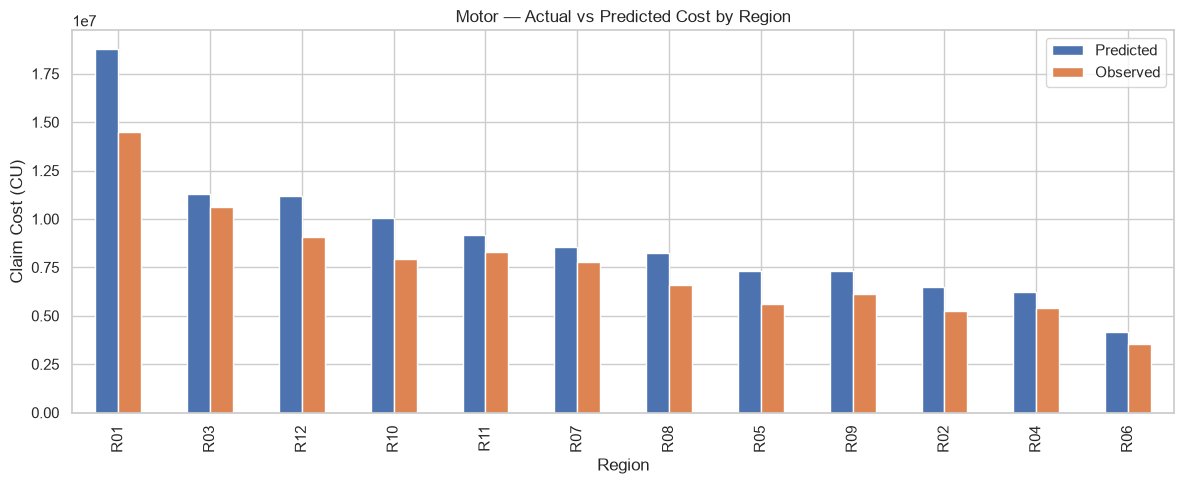

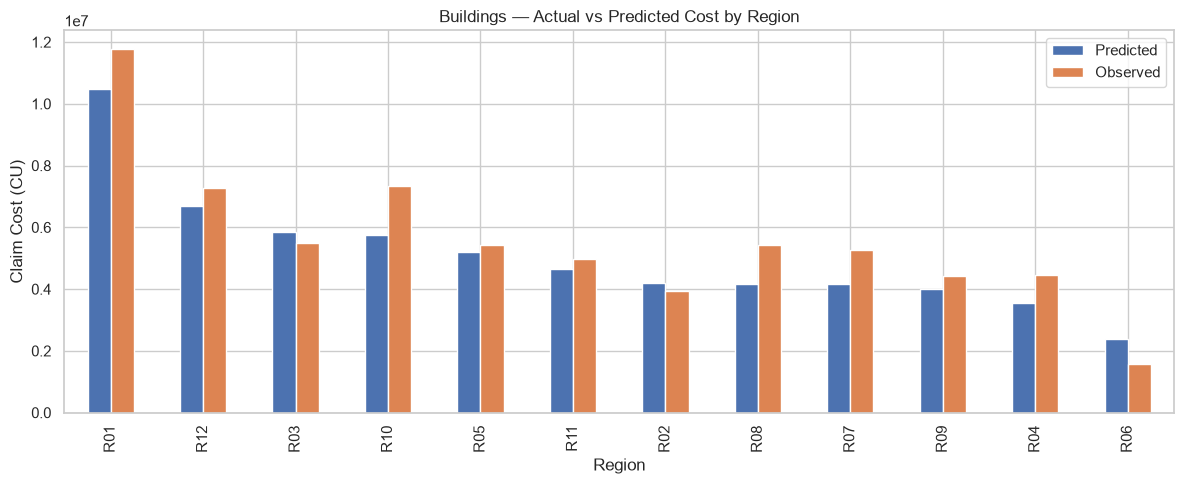

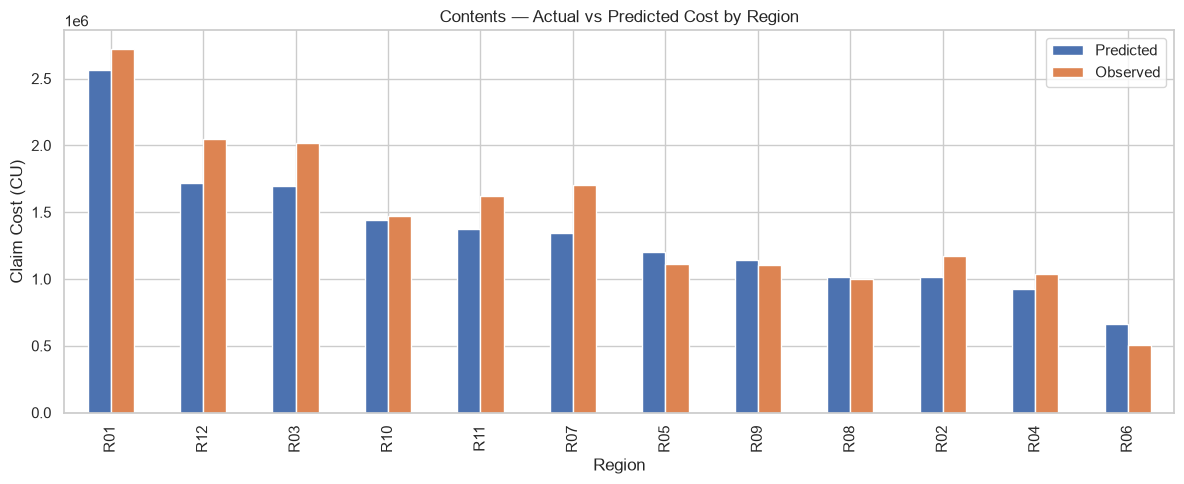

In [29]:
import matplotlib.pyplot as plt

for line in LINES:

    df = valid_split[line].copy()

    df["prediction"] = validation_predictions[line]

    comparison = (
        df.groupby("region")[["prediction", TARGET]]
        .sum()
        .sort_values("prediction", ascending=False)
    )

    ax = comparison.plot(
        kind="bar",
        figsize=(12, 5)
    )

    ax.set_title(
        f"{line.capitalize()} — Actual vs Predicted Cost by Region"
    )

    ax.set_xlabel("Region")
    ax.set_ylabel("Claim Cost (CU)")
    ax.legend(["Predicted", "Observed"])

    plt.tight_layout()
    plt.show()

Step 9 — Refit using all 2021–2024 observations
Once the validation works, retrain each model using all historical policy-periods.

In [30]:
final_models = {}

for line in LINES:

    print(f"\nRefitting {line} on 2021–2024...")

    df = train[line]

    if (df[TARGET] < 0).any():
        raise ValueError(
            f"{line} has negative targets. "
            "Review these before final fitting."
        )

    X = df[features[line]]

    y = df[TARGET] / df[EXPOSURE]

    weights = df[EXPOSURE]

    model = build_model(df, features[line])

    model.fit(
        X,
        y,
        regressor__sample_weight=weights
    )

    final_models[line] = model

    print(f"Final {line} model fitted.")


Refitting motor on 2021–2024...
Final motor model fitted.

Refitting buildings on 2021–2024...
Final buildings model fitted.

Refitting contents on 2021–2024...
Final contents model fitted.


Step 10 — Predict 2025 and create the submission

In [31]:
predictions = []

for line in LINES:

    df = test[line].copy()

    X_test = df[features[line]]

    # Annualised risk premium
    predicted_pure_premium = final_models[line].predict(X_test)

    # Expected cost for actual insured period
    expected_cost = (
        predicted_pure_premium
        * df[EXPOSURE].to_numpy()
    )

    result = pd.DataFrame({
        "row_id": df["row_id"].to_numpy(),
        "prediction": np.maximum(expected_cost, 0)
    })

    predictions.append(result)

submission = pd.concat(predictions, ignore_index=True)

In [ ]:
sample_submission = datasets["sample_submission"].copy()

assert submission["row_id"].is_unique
assert sample_submission["row_id"].is_unique

assert set(submission["row_id"]) == set(
    sample_submission["row_id"]
)

submission = sample_submission[["row_id"]].merge(
    submission,
    on="row_id",
    how="left",
    validate="one_to_one"
)

assert submission["prediction"].notna().all()
assert np.isfinite(submission["prediction"]).all()
assert (submission["prediction"] >= 0).all()

submission.to_csv("submission_v1.csv", index=False)

display(submission.head())

,row_id,prediction
0,M02409311,217.398047
1,M02409312,490.300581
2,M02409313,334.360140
3,M02409314,231.862377
4,M02409315,453.740829
